In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 160)

fund_master = pd.read_csv('01_fund_master_cleaned.csv', parse_dates=['launch_date'])
nav_history = pd.read_csv('02_nav_history_cleaned.csv', parse_dates=['date'])
aum_by_house = pd.read_csv('03_aum_by_fund_house_cleaned.csv', parse_dates=['date'])
sip_inflows = pd.read_csv('04_monthly_sip_inflows_cleaned.csv', parse_dates=['month_date'])
category_inflows = pd.read_csv('05_category_inflows_cleaned.csv', parse_dates=['month_date'])
folio_counts = pd.read_csv('06_industry_folio_count_cleaned.csv', parse_dates=['month_date'])
scheme_perf = pd.read_csv('07_scheme_performance_cleaned.csv')
benchmarks = pd.read_csv('10_benchmark_indices_cleaned.csv', parse_dates=['date'])

nav_history = nav_history.sort_values(['amfi_code', 'date']).reset_index(drop=True)
nav_history['daily_return'] = nav_history.groupby('amfi_code')['nav'].pct_change()

print(f"Schemes: {fund_master['amfi_code'].nunique()}")
print(f"NAV history: {nav_history['date'].min().date()} to {nav_history['date'].max().date()}, "
      f"{nav_history.groupby('amfi_code').size().iloc[0]} trading days/scheme")
fund_master.head()

Schemes: 40
NAV history: 2022-01-03 to 2026-05-29, 1150 trading days/scheme


,amfi_code,fund_house,scheme_name,category,sub_category,plan,launch_date,benchmark,expense_ratio_pct,exit_load_pct,min_sip_amount,min_lumpsum_amount,fund_manager,risk_category,sebi_category_code
0,100016,HDFC Mutual Fund,HDFC Top 100 Fund - Regular Plan - Growth,Equity,Large Cap,Regular,1996-09-11,NIFTY 100 TRI,1.55,1.0,500,1000,Rahul Baijal,Moderate,EC01
1,100025,HDFC Mutual Fund,HDFC Short Term Debt Fund - Regular - Growth,Debt,Short Duration,Regular,2002-06-25,CRISIL Short Term Bond Index,0.56,0.5,500,1000,Anil Bamboli,Low,DC02
2,100033,HDFC Mutual Fund,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,Equity,Mid Cap,Regular,2007-06-25,NIFTY Midcap 150 TRI,1.38,1.0,500,1000,Chirag Setalvad,High,EC02
3,101206,Aditya Birla Sun Life Mutual Fund,ABSL Frontline Equity Fund - Regular - Growth,Equity,Large Cap,Regular,2002-08-30,NIFTY 100 TRI,1.60,1.0,500,1000,Mahesh Patil,Moderate,EC01
4,101207,Aditya Birla Sun Life Mutual Fund,ABSL Small Cap Fund - Regular - Growth,Equity,Small Cap,Regular,2007-05-31,BSE 250 SmallCap TRI,1.53,1.0,500,1000,Mircea Ciobanu,Very High,EC03


In [ ]:
def historical_var_cvar(returns, confidence=0.95):
    r = returns.dropna()
    var = np.percentile(r, (1 - confidence) * 100)
    cvar = r[r <= var].mean()
    return var, cvar

var_rows = []
for code_, g in nav_history.groupby('amfi_code'):
    var95, cvar95 = historical_var_cvar(g['daily_return'], confidence=0.95)
    var_rows.append({
        'amfi_code': code_,
        'var_95_daily': var95,
        'cvar_95_daily': cvar95,
        'n_obs': g['daily_return'].notna().sum(),
    })

var_cvar_df = pd.DataFrame(var_rows).merge(
    fund_master[['amfi_code', 'scheme_name', 'fund_house', 'category', 'sub_category', 'risk_category']],
    on='amfi_code'
).merge(
    scheme_perf[['amfi_code', 'sharpe_ratio', 'std_dev_ann_pct', 'max_drawdown_pct']],
    on='amfi_code'
)


var_cvar_df['var_95_annualized_pct'] = var_cvar_df['var_95_daily'] * np.sqrt(252) * 100
var_cvar_df['cvar_95_annualized_pct'] = var_cvar_df['cvar_95_daily'] * np.sqrt(252) * 100

var_cvar_df = var_cvar_df[[
    'amfi_code', 'scheme_name', 'fund_house', 'category', 'sub_category', 'risk_category',
    'var_95_daily', 'cvar_95_daily', 'var_95_annualized_pct', 'cvar_95_annualized_pct',
    'sharpe_ratio', 'std_dev_ann_pct', 'max_drawdown_pct', 'n_obs'
]].sort_values('var_95_daily').reset_index(drop=True)

var_cvar_df.to_csv('var_cvar_report.csv', index=False)
print(f"Saved var_cvar_report.csv ({len(var_cvar_df)} schemes)")
var_cvar_df.head(10)

Saved var_cvar_report.csv (40 schemes)


,amfi_code,scheme_name,fund_house,category,sub_category,risk_category,var_95_daily,cvar_95_daily,var_95_annualized_pct,cvar_95_annualized_pct,sharpe_ratio,std_dev_ann_pct,max_drawdown_pct,n_obs
0,119599,SBI Small Cap Fund - Direct Plan - Growth,SBI Mutual Fund,Equity,Small Cap,Very High,-0.026859,-0.032384,-42.638031,-51.408201,0.93,25.0,-24.78,1149
1,119095,Axis Small Cap Fund - Regular - Growth,Axis Mutual Fund,Equity,Small Cap,Very High,-0.026188,-0.031667,-41.572835,-50.270270,0.84,25.0,-14.45,1149
2,101207,ABSL Small Cap Fund - Regular - Growth,Aditya Birla Sun Life Mutual Fund,Equity,Small Cap,Very High,-0.026021,-0.032459,-41.307451,-51.527159,0.90,25.0,-23.61,1149
3,118634,Nippon India Small Cap Fund - Regular - Growth,Nippon India Mutual Fund,Equity,Small Cap,Very High,-0.025438,-0.032304,-40.381750,-51.281126,0.81,25.0,-30.87,1149
4,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Equity,Small Cap,Very High,-0.024507,-0.030595,-38.903739,-48.568476,0.94,25.0,-13.35,1149
5,149324,DSP Small Cap Fund - Regular - Growth,DSP Mutual Fund,Equity,Small Cap,Very High,-0.023483,-0.031036,-37.278217,-49.268523,0.80,25.0,-17.01,1149
6,102886,UTI Mid Cap Fund - Regular - Growth,UTI Mutual Fund,Equity,Mid Cap,High,-0.019220,-0.023251,-30.511254,-36.909596,0.82,19.0,-13.43,1149
7,100033,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,HDFC Mutual Fund,Equity,Mid Cap,High,-0.019034,-0.023456,-30.214801,-37.234869,0.87,19.0,-13.67,1149
8,120505,ICICI Pru Midcap Fund - Regular - Growth,ICICI Prudential Mutual Fund,Equity,Mid Cap,High,-0.018892,-0.024342,-29.989781,-38.641839,0.95,19.0,-21.84,1149
9,119094,Axis Midcap Fund - Regular - Growth,Axis Mutual Fund,Equity,Mid Cap,High,-0.018480,-0.024260,-29.336529,-38.511651,0.80,19.0,-32.38,1149


In [3]:
print("5 schemes with the WORST (most negative) 95% daily VaR:")
var_cvar_df.nsmallest(5, 'var_95_daily')[['scheme_name', 'risk_category', 'var_95_daily', 'cvar_95_daily']]

5 schemes with the WORST (most negative) 95% daily VaR:


,scheme_name,risk_category,var_95_daily,cvar_95_daily
0,SBI Small Cap Fund - Direct Plan - Growth,Very High,-0.026859,-0.032384
1,Axis Small Cap Fund - Regular - Growth,Very High,-0.026188,-0.031667
2,ABSL Small Cap Fund - Regular - Growth,Very High,-0.026021,-0.032459
3,Nippon India Small Cap Fund - Regular - Growth,Very High,-0.025438,-0.032304
4,SBI Small Cap Fund - Regular Plan - Growth,Very High,-0.024507,-0.030595


In [4]:
print("5 schemes with the BEST (least negative) 95% daily VaR:")
var_cvar_df.nlargest(5, 'var_95_daily')[['scheme_name', 'risk_category', 'var_95_daily', 'cvar_95_daily']]

5 schemes with the BEST (least negative) 95% daily VaR:


,scheme_name,risk_category,var_95_daily,cvar_95_daily
39,ICICI Pru Liquid Fund - Regular - Growth,Low,-0.000222,-0.000373
38,ABSL Liquid Fund - Regular - Growth,Low,-0.000269,-0.000422
37,Kotak Liquid Fund - Regular - Growth,Low,-0.000285,-0.000411
36,HDFC Short Term Debt Fund - Regular - Growth,Low,-0.003793,-0.004994
35,Nippon India Gilt Securities Fund - Regular - ...,Low,-0.003804,-0.004919


In [5]:
key_funds = scheme_perf.sort_values('aum_crore', ascending=False).head(5)[['amfi_code', 'scheme_name', 'sub_category', 'aum_crore']]
key_funds

,amfi_code,scheme_name,sub_category,aum_crore
35,148568,Mirae Asset Emerging Bluechip Fund - Regular -...,Large & Mid Cap,49046
29,120842,Kotak Emerging Equity Fund - Regular - Growth,Mid Cap,47469
11,118634,Nippon India Small Cap Fund - Regular - Growth,Small Cap,43630
37,149322,DSP Top 100 Equity Fund - Regular - Growth,Large Cap,41828
7,102886,UTI Mid Cap Fund - Regular - Growth,Mid Cap,41728


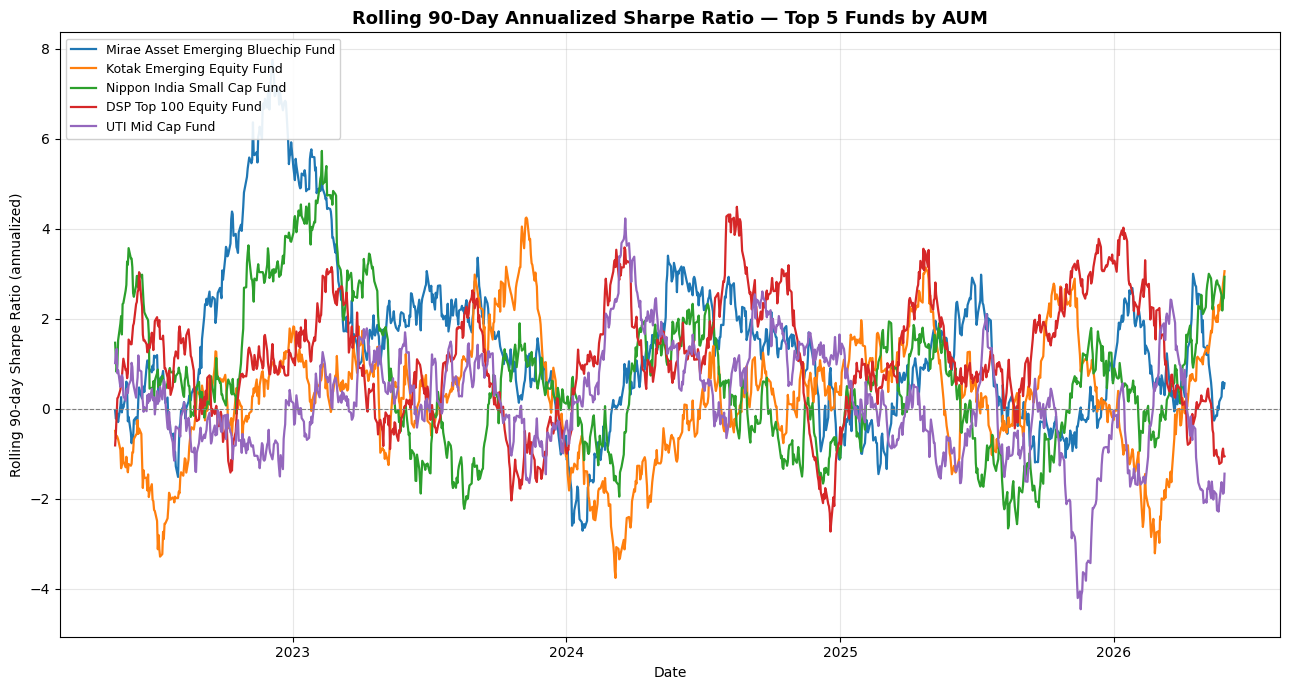

Saved rolling_sharpe_chart.png


In [ ]:
fig, ax = plt.subplots(figsize=(13, 7))

for _, row in key_funds.iterrows():
    code_ = row['amfi_code']
    g = nav_history[nav_history['amfi_code'] == code_].set_index('date')['daily_return']
    rolling_sharpe = (g.rolling(90).mean() / g.rolling(90).std()) * np.sqrt(252)
    label = row['scheme_name'].split(' - ')[0]  
    ax.plot(rolling_sharpe.index, rolling_sharpe.values, label=label, linewidth=1.6)

ax.axhline(0, color='grey', linewidth=0.8, linestyle='--')
ax.set_title('Rolling 90-Day Annualized Sharpe Ratio — Top 5 Funds by AUM', fontsize=13, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Rolling 90-day Sharpe Ratio (annualized)')
ax.legend(loc='upper left', fontsize=9, framealpha=0.9)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig('rolling_sharpe_chart.png', dpi=150)
plt.show()
print("Saved rolling_sharpe_chart.png")

In [7]:
fund_master_c = fund_master.copy()
fund_master_c['launch_year'] = fund_master_c['launch_date'].dt.year

cohort_base = fund_master_c.merge(
    scheme_perf[['amfi_code', 'aum_crore', 'sharpe_ratio', 'return_3yr_pct', 'expense_ratio_pct']],
    on='amfi_code', suffixes=('', '_perf')
)

launch_cohorts = cohort_base.groupby('launch_year').agg(
    num_funds=('amfi_code', 'count'),
    total_aum_crore=('aum_crore', 'sum'),
    avg_expense_ratio_pct=('expense_ratio_pct', 'mean'),
    avg_sharpe_ratio=('sharpe_ratio', 'mean'),
    avg_return_3yr_pct=('return_3yr_pct', 'mean'),
).reset_index()

top_subcat_per_cohort = cohort_base.groupby('launch_year')['sub_category'] \
    .agg(lambda s: s.mode().iloc[0]).rename('dominant_sub_category')

launch_cohorts = launch_cohorts.merge(top_subcat_per_cohort, on='launch_year') \
    .sort_values('launch_year').reset_index(drop=True)

launch_cohorts

,launch_year,num_funds,total_aum_crore,avg_expense_ratio_pct,avg_sharpe_ratio,avg_return_3yr_pct,dominant_sub_category
0,1996,1,6434,1.550000,1.060000,14.840000,Large Cap
1,1999,1,30030,0.550000,1.330000,5.310000,Gilt
2,2000,3,70446,1.043333,2.530000,7.770000,Gilt
3,2001,2,59400,0.815000,4.295000,9.725000,Index/ETF
4,2002,2,51453,1.080000,1.410000,10.575000,Large Cap
5,2003,1,41828,1.540000,0.920000,12.820000,Large Cap
6,2004,5,93810,1.278000,1.986000,13.726000,Mid Cap
7,2005,2,53497,1.615000,0.915000,13.795000,Flexi Cap
8,2006,2,52123,1.575000,0.890000,14.760000,Large Cap
9,2007,4,147391,1.497500,0.882500,19.317500,Mid Cap


In [8]:
sip_yearly = sip_inflows.copy()
sip_yearly['year'] = sip_yearly['month_date'].dt.year
sip_yearly_cohort = sip_yearly.groupby('year').agg(
    total_sip_inflow_crore=('sip_inflow_crore', 'sum'),
    avg_active_sip_accounts_crore=('active_sip_accounts_crore', 'mean'),
    avg_new_sip_accounts_lakh=('new_sip_accounts_lakh', 'mean'),
).reset_index()
sip_yearly_cohort

,year,total_sip_inflow_crore,avg_active_sip_accounts_crore,avg_new_sip_accounts_lakh
0,2022,149437,5.558333,8.862500
1,2023,184763,6.609167,9.079167
2,2024,269781,7.892500,9.212500
3,2025,335740,8.698333,12.420833


In [ ]:
sip_cont = sip_inflows.sort_values('month_date').copy()
sip_cont['accounts_change_crore'] = sip_cont['active_sip_accounts_crore'].diff()
sip_cont['accounts_mom_pct'] = sip_cont['active_sip_accounts_crore'].pct_change() * 100
sip_cont['inflow_mom_pct'] = sip_cont['sip_inflow_crore'].pct_change() * 100
sip_cont['at_risk_month'] = sip_cont['accounts_mom_pct'] < 0   

at_risk_months = sip_cont[sip_cont['at_risk_month']]
print(f"Months where active SIP accounts declined MoM: {len(at_risk_months)} / {len(sip_cont)} "
      f"({len(at_risk_months)/len(sip_cont)*100:.1f}%)")
sip_cont[['month_date', 'active_sip_accounts_crore', 'accounts_mom_pct', 'inflow_mom_pct', 'at_risk_month']].tail(15)

Months where active SIP accounts declined MoM: 2 / 48 (4.2%)


,month_date,active_sip_accounts_crore,accounts_mom_pct,inflow_mom_pct,at_risk_month
33,2024-10-01,8.30,0.973236,3.321229,False
34,2024-11-01,8.40,1.204819,-0.011847,False
35,2024-12-01,8.50,1.190476,4.498420,False
36,2025-01-01,8.22,-3.294118,-0.222987,True
37,2025-02-01,8.30,0.973236,-1.518939,False
38,2025-03-01,8.11,-2.289157,-0.280780,True
39,2025-04-01,8.38,3.329223,2.723135,False
40,2025-05-01,8.50,1.431981,0.210273,False
41,2025-06-01,8.62,1.411765,2.195743,False
42,2025-07-01,8.75,1.508121,4.363130,False


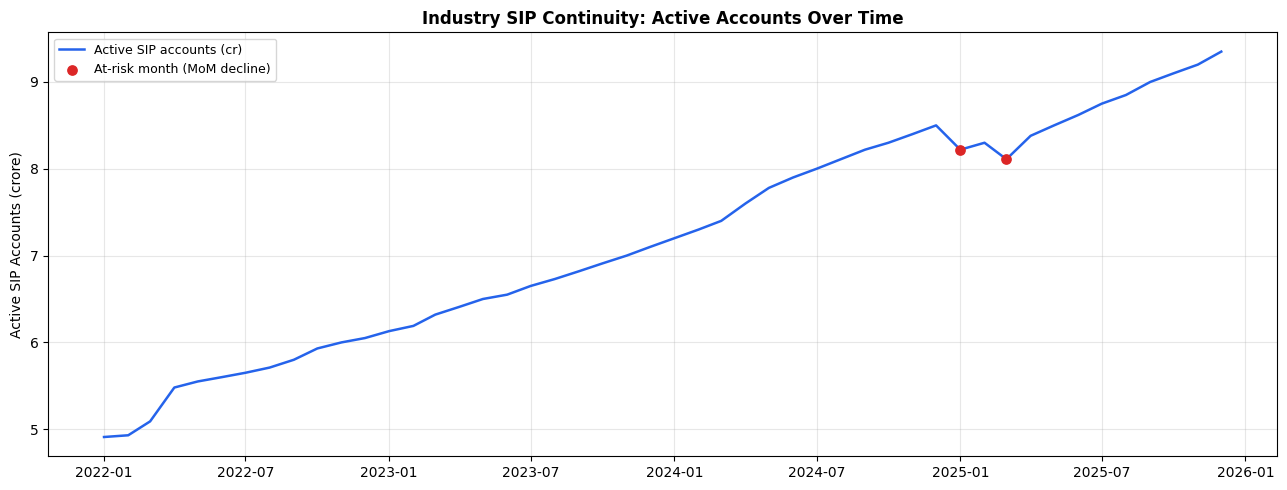

In [10]:
fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.plot(sip_cont['month_date'], sip_cont['active_sip_accounts_crore'], color='#2563eb', linewidth=1.8, label='Active SIP accounts (cr)')
ax1.scatter(at_risk_months['month_date'], at_risk_months['active_sip_accounts_crore'], color='#dc2626', zorder=5, label='At-risk month (MoM decline)', s=45)
ax1.set_ylabel('Active SIP Accounts (crore)')
ax1.set_title('Industry SIP Continuity: Active Accounts Over Time', fontsize=12, fontweight='bold')
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [11]:
RISK_MAP = {
    'Low': ['Low'],
    'Moderate': ['Moderate', 'Moderately High'],
    'High': ['High', 'Very High'],
}

def recommend(risk_appetite, n=3, data=scheme_perf):
    key = risk_appetite.strip().title()
    if key not in RISK_MAP:
        raise ValueError(f"risk_appetite must be one of {list(RISK_MAP)}")
    pool = data[data['risk_grade'].isin(RISK_MAP[key])].copy()
    pool = pool.sort_values('sharpe_ratio', ascending=False).head(n)
    return pool[['scheme_name', 'fund_house', 'sub_category', 'risk_grade',
                 'sharpe_ratio', 'return_3yr_pct', 'std_dev_ann_pct']].reset_index(drop=True)

for risk_appetite in ['Low', 'Moderate', 'High']:
    print(f"\n=== Recommendation table: {risk_appetite} risk appetite ===")
    display(recommend(risk_appetite, n=3))


=== Recommendation table: Low risk appetite ===


,scheme_name,fund_house,sub_category,risk_grade,sharpe_ratio,return_3yr_pct,std_dev_ann_pct
0,ICICI Pru Liquid Fund - Regular - Growth,ICICI Prudential Mutual Fund,Liquid,Low,7.68,7.68,0.5
1,Kotak Liquid Fund - Regular - Growth,Kotak Mahindra Mutual Fund,Liquid,Low,6.18,6.18,0.5
2,ABSL Liquid Fund - Regular - Growth,Aditya Birla Sun Life Mutual Fund,Liquid,Low,5.14,5.14,0.5



=== Recommendation table: Moderate risk appetite ===


,scheme_name,fund_house,sub_category,risk_grade,sharpe_ratio,return_3yr_pct,std_dev_ann_pct
0,HDFC Top 100 Fund - Regular Plan - Growth,HDFC Mutual Fund,Large Cap,Moderate,1.06,14.84,14.0
1,Mirae Asset Large Cap Fund - Regular - Growth,Mirae Asset Mutual Fund,Large Cap,Moderate,1.06,14.81,14.0
2,ICICI Pru Bluechip Fund - Direct - Growth,ICICI Prudential Mutual Fund,Large Cap,Moderate,1.03,14.41,14.0



=== Recommendation table: High risk appetite ===


,scheme_name,fund_house,sub_category,risk_grade,sharpe_ratio,return_3yr_pct,std_dev_ann_pct
0,Kotak Emerging Equity Fund - Regular - Growth,Kotak Mahindra Mutual Fund,Mid Cap,High,0.96,18.23,19.0
1,ICICI Pru Midcap Fund - Regular - Growth,ICICI Prudential Mutual Fund,Mid Cap,High,0.95,18.08,19.0
2,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Small Cap,Very High,0.94,23.39,25.0


In [ ]:
equity_perf = scheme_perf.merge(fund_master[['amfi_code', 'category']], on='amfi_code')
equity_perf = equity_perf[equity_perf['category'] == 'Equity'].copy()

equity_perf['aum_weight'] = equity_perf['aum_crore'] / equity_perf['aum_crore'].sum()
hhi_fund_level = (equity_perf['aum_weight'] ** 2).sum() * 10000


subcat_share = equity_perf.groupby('sub_category')['aum_crore'].sum()
subcat_share = subcat_share / subcat_share.sum()
hhi_subcat_level = (subcat_share ** 2).sum() * 10000


latest_date = aum_by_house['date'].max()
latest_house = aum_by_house[aum_by_house['date'] == latest_date].copy()
latest_house['weight'] = latest_house['aum_crore'] / latest_house['aum_crore'].sum()
hhi_house_level = (latest_house['weight'] ** 2).sum() * 10000

def hhi_label(v):
    if v < 1500: return 'Unconcentrated'
    if v < 2500: return 'Moderate concentration'
    return 'Highly concentrated'

hhi_summary = pd.DataFrame([
    {'level': 'Equity funds by individual fund AUM share', 'hhi': hhi_fund_level, 'interpretation': hhi_label(hhi_fund_level)},
    {'level': 'Equity funds by sub-category AUM share', 'hhi': hhi_subcat_level, 'interpretation': hhi_label(hhi_subcat_level)},
    {'level': f'Whole industry by fund-house AUM share ({latest_date.date()})', 'hhi': hhi_house_level, 'interpretation': hhi_label(hhi_house_level)},
])
hhi_summary

,level,hhi,interpretation
0,Equity funds by individual fund AUM share,390.323299,Unconcentrated
1,Equity funds by sub-category AUM share,2586.592378,Highly concentrated
2,Whole industry by fund-house AUM share (2025-1...,1282.032939,Unconcentrated


In [13]:
print("Equity AUM share by sub-category (weights feeding HHI #2 above):")
subcat_share.sort_values(ascending=False).apply(lambda x: f"{x*100:.1f}%")

Equity AUM share by sub-category (weights feeding HHI #2 above):


sub_category
Large Cap          37.9%
Mid Cap            23.2%
Small Cap          23.0%
Flexi Cap           6.2%
Large & Mid Cap     5.7%
Index/ETF           2.4%
Index               0.9%
ELSS                0.3%
Value               0.3%
Name: aum_crore, dtype: str